# Heart Disease Classification

## Import Modules and Load Data

In [88]:
import pandas as pd
import numpy as np

heart_df = pd.read_csv("heart.csv")

In [89]:
heart_df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [90]:
heart_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


## Seperate Features and Labels

In [91]:
X = heart_df.drop("HeartDisease", axis=1)
y = heart_df["HeartDisease"]

## EDA is done seperatly, results are listed here

### Raw Results

- ST Slope: When it is Down and Flat, Heart Disease is much more likely
            When it is Up, Heart Disease is unlikely

- Chest Pain Type: When it is ASY, Heart Disease is much more likely
                   When it is ATA, Heart Disease is unlikely
                   When it is NAP, Heart Disease is less likely
                   When it is TA, Heart Disease is less likely

- Exercise Induced Angina: When it is No, Heart Disease is less likely
                           When it is Yes, Heart Disease is much more likely

- Maximum HR: When Max HR is low, Heart Disease is likely

- Sex: Males are more likely to have a heart disease by a great margin, it should be kept in mind that most of the subjects in the dataset is male

- Resting BP: It is very similar in both groups

- Oldpeak: Oldpeak is generally greater in patients with Heart Disease

- Cholestrol: Cholestrol means seems close in both groups, 
              however there are a lot of patients with missing cholestrol values

- Resting ECG: Most patients have normal, and normal does not seperate between classes
               When it is LVH, Heart Disease is slightly more likely
               When it is ST, Heart Disease is likely

- Fasting Blood Sugar: When Fasting BS is 0, it does not seperate between classes
                     When Fasting BS is 1, Heart Disease is much more likely

- Age: Older people are slightly more likely to get Heart Disease



### How This Will Be Used

- Cholestrol is not going to be used as a feature for now, due to a lot of missing values

- Resting BP is not going to be used as a feature for now, due to low usefulness

- Age and Sex are different than other features, because of this they will be used differently

- Rest of the features are going to be used to train the model

#### Architecture

- 4 different models are going to be trained 
    * Male and above median age
    * Male and below median age
    * Female and above median age
    * Female and below median age

    This way importance of age and sex are still present, 
    but it will reduce the wrong predictionn 
    as model would be more likely predict heart disease for older male
    and young female with heart disease might be missed

- Categorical Data will be used with OneHotEncoder

- Different ML algorithms will be compared to get the best result



## Machine Learning: Classification

In [92]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score

RANDOM_STATE = 42

### Build the four Sex/Age subgroups

Cholesterol and RestingBP are dropped, and the data is split into 4 groups by Sex and whether Age is above/below the overall median.

In [114]:
model_features = [
    "ChestPainType", "FastingBS", "RestingECG",
    "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope",
]
categorical_features = ["ChestPainType", "RestingECG", "ExerciseAngina", "FastingBS", "ST_Slope"]
numeric_features = [ "MaxHR", "Oldpeak"]

age_median = heart_df["Age"].median()
print(f"Median age: {age_median}")

subgroups = {}
for sex in ["M", "F"]:
    for age_band, above in [("above_median", True), ("below_median", False)]:
        age_mask = (heart_df["Age"] >= age_median) if above else (heart_df["Age"] < age_median)
        mask = (heart_df["Sex"] == sex) & age_mask
        key = f"{sex}_{age_band}"
        subgroups[key] = heart_df.loc[mask, model_features + ["HeartDisease"]]

for key, df in subgroups.items():
    print(f"{key}: n={len(df)}, positive rate={df['HeartDisease'].mean():.2f}")

Median age: 54.0
M_above_median: n=405, positive rate=0.74
M_below_median: n=320, positive rate=0.50
F_above_median: n=93, positive rate=0.39
F_below_median: n=100, positive rate=0.14


### Preprocessing and candidate models

Categorical features go through `OneHotEncoder`, numeric features are scaled. A few different algorithms are compared per subgroup.

In [94]:
def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features),
    ])

models = {
    "logreg": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "random_forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "knn": KNeighborsClassifier(),
    "svc": SVC(probability=True, random_state=RANDOM_STATE),
}

### Train and evaluate per subgroup

Note: splitting into 4 subgroups leaves ~150-350 rows each, so test-set metrics here will be noisy — treat this as a first pass, not a final comparison.

In [95]:
results = []

for group_name, df in subgroups.items():
    X_g = df[model_features]
    y_g = df["HeartDisease"]
    X_train, X_test, y_train, y_test = train_test_split(
        X_g, y_g, test_size=0.2, stratify=y_g, random_state=RANDOM_STATE
    )

    for model_name, model in models.items():
        pipe = Pipeline([
            ("preprocess", make_preprocessor()),
            ("model", model),
        ])
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)[:, 1]

        results.append({
            "group": group_name,
            "model": model_name,
            "n_train": len(X_train),
            "n_test": len(X_test),
            "accuracy": (y_pred == y_test).mean(),
            "roc_auc": roc_auc_score(y_test, y_proba),
        })

results_df = pd.DataFrame(results).sort_values(["group", "roc_auc"], ascending=[True, False])
results_df

,group,model,n_train,n_test,accuracy,roc_auc
11,F_above_median,svc,74,19,0.736842,0.761905
8,F_above_median,logreg,74,19,0.736842,0.726190
10,F_above_median,knn,74,19,0.736842,0.684524
9,F_above_median,random_forest,74,19,0.684211,0.654762
12,F_below_median,logreg,80,20,1.000000,1.000000
13,F_below_median,random_forest,80,20,1.000000,1.000000
15,F_below_median,svc,80,20,0.850000,0.960784
14,F_below_median,knn,80,20,0.850000,0.784314
1,M_above_median,random_forest,324,81,0.814815,0.848413
0,M_above_median,logreg,324,81,0.814815,0.834127


## Hyperparameter Tuning with Optuna

**`RepeatedStratifiedKFold(n_splits=3, n_repeats=5)`** on the 80% training portion of each subgroup is used:
- **3 splits** → each validation fold is ~1/3 of the (small) subgroup, so it keeps enough positive cases for a stable F1/ROC-AUC.
- **5 repeats** → 15 fits per trial with reshuffled splits, giving a meaningful mean ± std.

Optuna maximizes **mean CV F1**. Each model is tuned in its own cell , and per subgroup we report CV **F1 / accuracy / ROC-AUC (mean ± std)** plus the best hyperparameters. The held-out 20% test set is only touched at the very end.

> Preprocessing lives *inside* the pipeline, so it is re-fit within every CV fold — no leakage into the score Optuna optimizes.

In [96]:
import optuna
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, cross_validate
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 30          # Optuna trials per subgroup — raise for a more thorough search
SCORING = {"f1": "f1", "accuracy": "accuracy", "roc_auc": "roc_auc"}

# 3 splits x 5 repeats = 15 fits per trial (see markdown above for why, not LOSO).
cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=RANDOM_STATE)

# 80/20 train/test split per subgroup, reused by every model cell below.
# Value is the tuple (X_train, X_test, y_train, y_test).
splits = {}
for group_name, df in subgroups.items():
    Xg, yg = df[model_features], df["HeartDisease"]
    splits[group_name] = train_test_split(
        Xg, yg, test_size=0.2, stratify=yg, random_state=RANDOM_STATE
    )

# Filled in by each model cell; consumed by the final test-set evaluation.
tuning_results = {}
builders = {}

def cv_report(estimator, X, y):
    """Mean +/- std of F1 / accuracy / ROC-AUC across the RepeatedStratifiedKFold splits."""
    res = cross_validate(estimator, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
    return {
        "f1_mean": res["test_f1"].mean(),        "f1_std": res["test_f1"].std(),
        "acc_mean": res["test_accuracy"].mean(), "acc_std": res["test_accuracy"].std(),
        "auc_mean": res["test_roc_auc"].mean(),  "auc_std": res["test_roc_auc"].std(),
    }

def tune(model_name, build_pipeline, suggest_params, n_trials=N_TRIALS):
    """Tune `build_pipeline` per subgroup with Optuna, maximizing mean CV F1."""
    builders[model_name] = build_pipeline
    per_group = {}
    for group_name, (X_tr, X_te, y_tr, y_te) in splits.items():
        def objective(trial, X_tr=X_tr, y_tr=y_tr):
            pipe = build_pipeline(suggest_params(trial))
            return cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1", n_jobs=-1).mean()
        study = optuna.create_study(
            direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        )
        study.optimize(objective, n_trials=n_trials)
        best = study.best_params
        per_group[group_name] = {"best_params": best, **cv_report(build_pipeline(best), X_tr, y_tr)}
    tuning_results[model_name] = per_group
    return per_group

def show(per_group):
    """Format one model's per-subgroup CV results as a table."""
    rows = [{
        "group": g,
        "cv_f1":  f"{r['f1_mean']:.3f} ± {r['f1_std']:.3f}",
        "cv_acc": f"{r['acc_mean']:.3f} ± {r['acc_std']:.3f}",
        "cv_auc": f"{r['auc_mean']:.3f} ± {r['auc_std']:.3f}",
        "best_params": r["best_params"],
    } for g, r in per_group.items()]
    return pd.DataFrame(rows)

In [97]:
# The 80/20 split above uses stratify=y, so each test set keeps the same positive
# rate as its training set (exact up to rounding on the small subgroups). Verify:
split_check = pd.DataFrame([
    {
        "group": g,
        "train_pos_rate": round(y_tr.mean(), 3),
        "test_pos_rate": round(y_te.mean(), 3),
        "diff": round(abs(y_tr.mean() - y_te.mean()), 3),
        "n_test": len(y_te),
        "pos_test": int(y_te.sum()),
    }
    for g, (X_tr, X_te, y_tr, y_te) in splits.items()
])
split_check

,group,train_pos_rate,test_pos_rate,diff,n_test,pos_test
0,M_above_median,0.735,0.741,0.006,81,60
1,M_below_median,0.500,0.500,0.000,64,32
2,F_above_median,0.392,0.368,0.023,19,7
3,F_below_median,0.138,0.150,0.012,20,3


### Logistic Regression

In [98]:
def build_logreg(params):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", LogisticRegression(max_iter=2000, solver="lbfgs",
                                     random_state=RANDOM_STATE, **params)),
    ])

def suggest_logreg(trial):
    return {
        "C": trial.suggest_float("C", 1e-3, 1e2, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }

show(tune("logreg", build_logreg, suggest_logreg))

,group,cv_f1,cv_acc,cv_auc,best_params
0,M_above_median,0.915 ± 0.016,0.870 ± 0.024,0.888 ± 0.034,"{'C': 0.12178636575064934, 'class_weight': None}"
1,M_below_median,0.870 ± 0.030,0.871 ± 0.030,0.939 ± 0.015,"{'C': 0.19069966103000435, 'class_weight': None}"
2,F_above_median,0.779 ± 0.075,0.822 ± 0.061,0.888 ± 0.043,"{'C': 0.11523531581704534, 'class_weight': 'ba..."
3,F_below_median,0.663 ± 0.132,0.884 ± 0.050,0.942 ± 0.030,"{'C': 2.443129500459008, 'class_weight': 'bala..."


### Random Forest

In [99]:
def build_rf(params):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE, **params)),
    ])

def suggest_rf(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }

show(tune("random_forest", build_rf, suggest_rf))

,group,cv_f1,cv_acc,cv_auc,best_params
0,M_above_median,0.912 ± 0.018,0.866 ± 0.027,0.880 ± 0.037,"{'n_estimators': 100, 'max_depth': 4, 'min_sam..."
1,M_below_median,0.888 ± 0.024,0.888 ± 0.024,0.951 ± 0.012,"{'n_estimators': 400, 'max_depth': 5, 'min_sam..."
2,F_above_median,0.799 ± 0.067,0.843 ± 0.054,0.921 ± 0.039,"{'n_estimators': 450, 'max_depth': 4, 'min_sam..."
3,F_below_median,0.547 ± 0.166,0.860 ± 0.060,0.909 ± 0.046,"{'n_estimators': 350, 'max_depth': 2, 'min_sam..."


### K-Nearest Neighbors

In [100]:
def build_knn(params):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", KNeighborsClassifier(**params)),
    ])

def suggest_knn(trial):
    return {
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 25),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "p": trial.suggest_categorical("p", [1, 2]),  # 1 = Manhattan, 2 = Euclidean
    }

show(tune("knn", build_knn, suggest_knn))

,group,cv_f1,cv_acc,cv_auc,best_params
0,M_above_median,0.920 ± 0.016,0.879 ± 0.023,0.875 ± 0.034,"{'n_neighbors': 19, 'weights': 'uniform', 'p': 1}"
1,M_below_median,0.884 ± 0.026,0.884 ± 0.026,0.936 ± 0.020,"{'n_neighbors': 6, 'weights': 'distance', 'p': 2}"
2,F_above_median,0.798 ± 0.108,0.857 ± 0.073,0.924 ± 0.045,"{'n_neighbors': 8, 'weights': 'distance', 'p': 1}"
3,F_below_median,0.479 ± 0.189,0.882 ± 0.039,0.831 ± 0.090,"{'n_neighbors': 7, 'weights': 'distance', 'p': 2}"


### Support Vector Classifier

In [101]:
def build_svc(params):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", SVC(random_state=RANDOM_STATE, **params)),
    ])

def suggest_svc(trial):
    return {
        "C": trial.suggest_float("C", 1e-2, 1e2, log=True),
        "gamma": trial.suggest_categorical("gamma", ["scale", "auto"]),
        "kernel": trial.suggest_categorical("kernel", ["rbf", "linear"]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }

show(tune("svc", build_svc, suggest_svc))

,group,cv_f1,cv_acc,cv_auc,best_params
0,M_above_median,0.912 ± 0.015,0.866 ± 0.024,0.875 ± 0.045,"{'C': 1.4552454171587246, 'gamma': 'auto', 'ke..."
1,M_below_median,0.875 ± 0.025,0.873 ± 0.026,0.943 ± 0.009,"{'C': 0.2563327159770393, 'gamma': 'scale', 'k..."
2,F_above_median,0.797 ± 0.060,0.827 ± 0.052,0.885 ± 0.042,"{'C': 0.027088517745104516, 'gamma': 'auto', '..."
3,F_below_median,0.652 ± 0.156,0.905 ± 0.041,0.936 ± 0.047,"{'C': 3.240199726509757, 'gamma': 'auto', 'ker..."


### Gaussian Naive Bayes

In [102]:
from sklearn.naive_bayes import GaussianNB

def build_gnb(params):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", GaussianNB(**params)),
    ])

def suggest_gnb(trial):
    # var_smoothing: portion of the largest feature variance added to all variances for stability.
    return {"var_smoothing": trial.suggest_float("var_smoothing", 1e-12, 1e-3, log=True)}

show(tune("gaussian_nb", build_gnb, suggest_gnb))

,group,cv_f1,cv_acc,cv_auc,best_params
0,M_above_median,0.885 ± 0.030,0.834 ± 0.037,0.871 ± 0.033,{'var_smoothing': 2.348881295853314e-09}
1,M_below_median,0.862 ± 0.033,0.861 ± 0.031,0.920 ± 0.022,{'var_smoothing': 0.0009239775350662543}
2,F_above_median,0.790 ± 0.080,0.832 ± 0.064,0.860 ± 0.066,{'var_smoothing': 6.830346849054047e-05}
3,F_below_median,0.596 ± 0.112,0.807 ± 0.068,0.964 ± 0.021,{'var_smoothing': 0.0009269749263529177}


## Final Evaluation on the Held-Out Test Set

For each model × subgroup, refit the best pipeline on the full 80% training split and score once on the untouched 20% test set. `cv_f1` is shown alongside so overfitting to CV noise can be spotted if it exists

In [103]:
def positive_scores(estimator, X):
    """Probabilities if available, else SVM decision-function scores — both fine for ROC-AUC."""
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X)[:, 1]
    return estimator.decision_function(X)

final_rows = []
for model_name, per_group in tuning_results.items():
    build = builders[model_name]
    for group_name, r in per_group.items():
        X_tr, X_te, y_tr, y_te = splits[group_name]
        pipe = build(r["best_params"]).fit(X_tr, y_tr)
        y_pred = pipe.predict(X_te)
        final_rows.append({
            "model": model_name,
            "group": group_name,
            "cv_f1": round(r["f1_mean"], 3),
            "test_f1": round(f1_score(y_te, y_pred), 3),
            "test_acc": round(accuracy_score(y_te, y_pred), 3),
            "test_auc": round(roc_auc_score(y_te, positive_scores(pipe, X_te)), 3),
            "n_test": len(y_te),
        })

final_test_df = (pd.DataFrame(final_rows)
                 .sort_values(["group", "test_f1"], ascending=[True, False])
                 .reset_index(drop=True))
final_test_df

,model,group,cv_f1,test_f1,test_acc,test_auc,n_test
0,knn,F_above_median,0.798,0.615,0.737,0.655,19
1,logreg,F_above_median,0.779,0.545,0.737,0.714,19
2,random_forest,F_above_median,0.799,0.545,0.737,0.750,19
3,gaussian_nb,F_above_median,0.790,0.545,0.737,0.786,19
4,svc,F_above_median,0.797,0.500,0.684,0.702,19
5,svc,F_below_median,0.652,1.000,1.000,1.000,20
6,random_forest,F_below_median,0.547,0.857,0.950,0.980,20
7,knn,F_below_median,0.479,0.800,0.950,0.784,20
8,logreg,F_below_median,0.663,0.750,0.900,1.000,20
9,gaussian_nb,F_below_median,0.596,0.400,0.700,0.706,20


## Ensembles: Voting + Stacking

Both reuse the per-subgroup best hyperparameters already found above (`builders` + `tuning_results`) — no re-tuning, just combine the tuned base models.

- **Soft voting** averages the base models' predicted probabilities. SVC is switched to `probability=True` here so it can contribute probabilities.
- **Stacking** feeds the base models' out-of-fold predictions into a logistic-regression meta-learner. `stack_method="auto"` uses SVC's `decision_function`, so no probability calibration is needed there.

Same CV protocol (RepeatedStratifiedKFold 3×5) for mean ± std, then a final score on the held-out test set.

In [104]:
from sklearn.ensemble import VotingClassifier, StackingClassifier

BASE_MODELS = ["logreg", "random_forest", "knn", "svc", "gaussian_nb"]

def tuned_estimators(group_name, prob_svc=False):
    """The tuned base pipelines for one subgroup, as (name, estimator) pairs."""
    estimators = []
    for name in BASE_MODELS:
        est = builders[name](tuning_results[name][group_name]["best_params"])
        if prob_svc and name == "svc":
            est.set_params(model__probability=True)   # soft voting needs probabilities
        estimators.append((name, est))
    return estimators

def make_ensemble(group_name, kind):
    """Build a fresh (unfitted) voting or stacking ensemble for a subgroup."""
    if kind == "voting":
        return VotingClassifier(
            estimators=tuned_estimators(group_name, prob_svc=True), voting="soft"
        )
    return StackingClassifier(
        estimators=tuned_estimators(group_name, prob_svc=False),
        final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        stack_method="auto", cv=5,
    )

ensemble_rows = []
ensemble_cv_f1 = {}          # {group: {"voting": f1_mean, "stacking": f1_mean}} for later selection
for group_name in splits:
    X_tr, X_te, y_tr, y_te = splits[group_name]
    for label in ["voting", "stacking"]:
        clf = make_ensemble(group_name, label)
        rep = cv_report(clf, X_tr, y_tr)
        ensemble_cv_f1.setdefault(group_name, {})[label] = rep["f1_mean"]
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_te)
        ensemble_rows.append({
            "ensemble": label,
            "group": group_name,
            "cv_f1":  f"{rep['f1_mean']:.3f} ± {rep['f1_std']:.3f}",
            "cv_acc": f"{rep['acc_mean']:.3f} ± {rep['acc_std']:.3f}",
            "cv_auc": f"{rep['auc_mean']:.3f} ± {rep['auc_std']:.3f}",
            "test_f1": round(f1_score(y_te, y_pred), 3),
            "test_acc": round(accuracy_score(y_te, y_pred), 3),
            "test_auc": round(roc_auc_score(y_te, positive_scores(clf, X_te)), 3),
        })

ensemble_df = (pd.DataFrame(ensemble_rows)
               .sort_values(["group", "ensemble"])
               .reset_index(drop=True))
ensemble_df

,ensemble,group,cv_f1,cv_acc,cv_auc,test_f1,test_acc,test_auc
0,stacking,F_above_median,0.765 ± 0.075,0.816 ± 0.061,0.908 ± 0.042,0.545,0.737,0.726
1,voting,F_above_median,0.798 ± 0.073,0.838 ± 0.060,0.914 ± 0.042,0.545,0.737,0.726
2,stacking,F_below_median,0.446 ± 0.256,0.888 ± 0.030,0.944 ± 0.034,0.800,0.950,1.000
3,voting,F_below_median,0.669 ± 0.121,0.897 ± 0.041,0.946 ± 0.034,1.000,1.000,1.000
4,stacking,M_above_median,0.911 ± 0.017,0.865 ± 0.024,0.879 ± 0.038,0.883,0.827,0.840
5,voting,M_above_median,0.912 ± 0.018,0.868 ± 0.027,0.886 ± 0.035,0.883,0.827,0.861
6,stacking,M_below_median,0.875 ± 0.027,0.873 ± 0.027,0.946 ± 0.009,0.833,0.844,0.886
7,voting,M_below_median,0.873 ± 0.024,0.873 ± 0.024,0.949 ± 0.010,0.800,0.812,0.885


## Confusion Matrices (Test Set)

For each subgroup we pick its **champion model** — the one with the highest CV F1 among all base models *and* the two ensembles — refit it on that subgroup's training split, and score its held-out test set. Then one **overall** matrix pools every subgroup's test predictions (this is the real end-to-end performance of the per-subgroup architecture).

         group      champion  cv_f1  test_f1
M_above_median           knn  0.920    0.883
M_below_median random_forest  0.888    0.806
F_above_median random_forest  0.799    0.545
F_below_median        voting  0.669    1.000


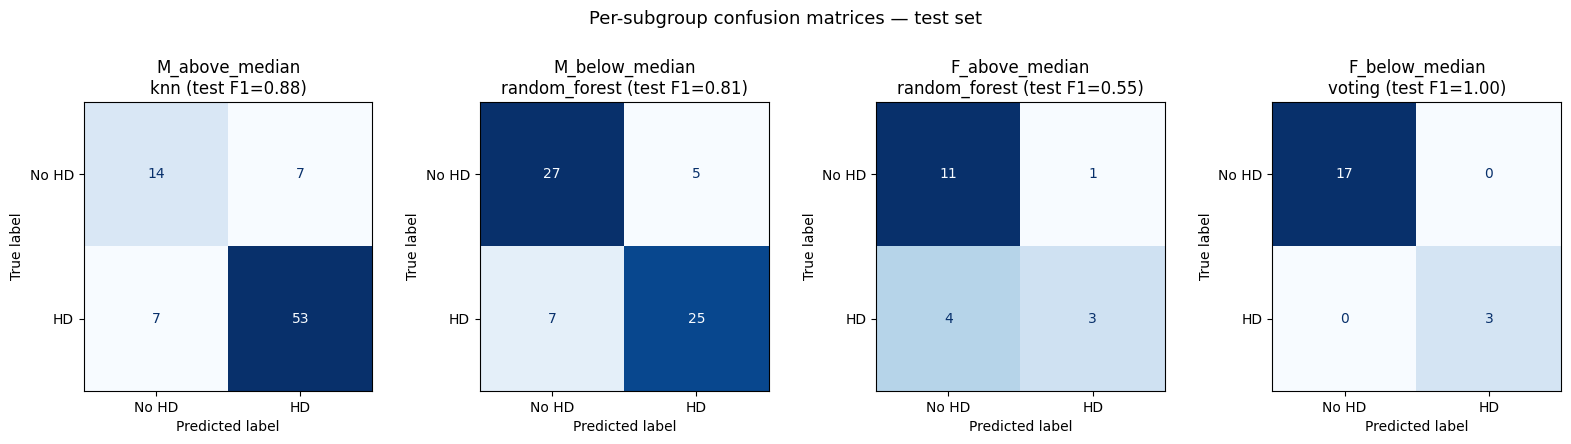

In [105]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def champion_for(group_name):
    """(name, cv_f1, unfitted_estimator) with the best CV F1 among base models + ensembles."""
    candidates = [
        (name, tuning_results[name][group_name]["f1_mean"],
         builders[name](tuning_results[name][group_name]["best_params"]))
        for name in tuning_results
    ]
    for label, f1 in ensemble_cv_f1.get(group_name, {}).items():
        candidates.append((label, f1, make_ensemble(group_name, label)))
    return max(candidates, key=lambda t: t[1])

# Fit each subgroup's champion, collect test predictions, and pool them for the overall view.
champions, all_true, all_pred = [], [], []
for group_name in splits:
    X_tr, X_te, y_tr, y_te = splits[group_name]
    name, cv_f1, est = champion_for(group_name)
    est.fit(X_tr, y_tr)
    y_pred = est.predict(X_te)
    champions.append({
        "group": group_name, "champion": name,
        "cv_f1": round(cv_f1, 3), "test_f1": round(f1_score(y_te, y_pred), 3),
        "y_true": np.asarray(y_te), "y_pred": y_pred,
    })
    all_true.extend(y_te)
    all_pred.extend(y_pred)

print(pd.DataFrame(champions)[["group", "champion", "cv_f1", "test_f1"]].to_string(index=False))

# Per-subgroup confusion matrices.
labels = ["No HD", "HD"]
fig, axes = plt.subplots(1, len(champions), figsize=(4 * len(champions), 4))
for ax, c in zip(axes, champions):
    cm = confusion_matrix(c["y_true"], c["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{c['group']}\n{c['champion']} (test F1={c['test_f1']:.2f})")
fig.suptitle("Per-subgroup confusion matrices — test set", y=1.05, fontsize=13)
plt.tight_layout()
plt.show()

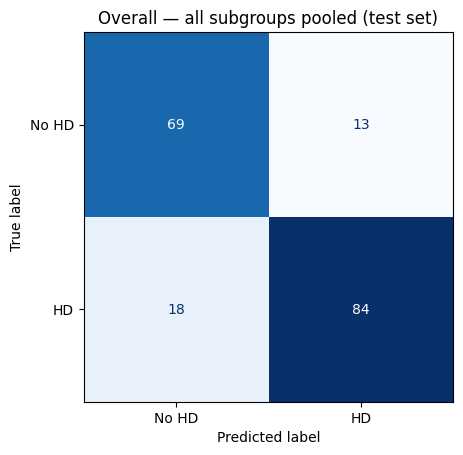

              precision    recall  f1-score   support

       No HD       0.79      0.84      0.82        82
          HD       0.87      0.82      0.84       102

    accuracy                           0.83       184
   macro avg       0.83      0.83      0.83       184
weighted avg       0.83      0.83      0.83       184



In [106]:
# Overall confusion matrix: all subgroups' champions pooled on the test set.
overall_cm = confusion_matrix(all_true, all_pred)
disp = ConfusionMatrixDisplay(overall_cm, display_labels=labels)
disp.plot(colorbar=False, cmap="Blues")
plt.title("Overall — all subgroups pooled (test set)")
plt.show()

print(classification_report(all_true, all_pred, target_names=labels))

# Full-Data Benchmark (no subgrouping)

A single model is trained with **Age and Sex added as features** instead of being used to split the data (`Cholesterol` and `RestingBP` are still dropped, same as the subgroup approach). Everything else matches the per-subgroup section: same 5 models, same search spaces, `RepeatedStratifiedKFold(3×5)`, Optuna maximizing F1, then a single held-out test evaluation.

**Same split as the subgroup approach:** since the 4 subgroups partition the dataset, the union of their train splits (734 rows) and the union of their test splits (184 rows) form one shared 80/20 split. This benchmark trains and tests on those exact rows, so every comparison below is on identical data — the only differences are pool-vs-split and Age/Sex as features vs split keys.

This is a benchmark for the per-subgroup architecture. All variables here are namespaced `full_*`.

In [107]:
# Full feature set: same as before, plus Age (numeric) and Sex (categorical).
full_features = ["Age", "Sex", "ChestPainType", "FastingBS", "RestingECG",
                 "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope"]
full_categorical = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "FastingBS", "ST_Slope"]
full_numeric = ["Age", "MaxHR", "Oldpeak"]

def make_full_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), full_categorical),
        ("num", StandardScaler(), full_numeric),
    ])

# Use the SAME split as the per-subgroup section. The 4 subgroups partition the dataset, so the
# union of their train splits and the union of their test splits form one shared 80/20 split.
# Age/Sex are recovered via the row indices the subgroup frames kept, so both approaches train
# and test on exactly the same rows.
shared_train_idx = np.concatenate([splits[g][0].index.to_numpy() for g in splits])
shared_test_idx  = np.concatenate([splits[g][1].index.to_numpy() for g in splits])
Xf_tr, yf_tr = heart_df.loc[shared_train_idx, full_features], heart_df.loc[shared_train_idx, "HeartDisease"]
Xf_te, yf_te = heart_df.loc[shared_test_idx,  full_features], heart_df.loc[shared_test_idx,  "HeartDisease"]

# Same model family and search spaces as the per-subgroup section.
full_model_specs = {
    "logreg": (
        lambda p: Pipeline([("preprocess", make_full_preprocessor()),
                            ("model", LogisticRegression(max_iter=2000, solver="lbfgs",
                                                         random_state=RANDOM_STATE, **p))]),
        lambda t: {"C": t.suggest_float("C", 1e-3, 1e2, log=True),
                   "class_weight": t.suggest_categorical("class_weight", [None, "balanced"])},
    ),
    "random_forest": (
        lambda p: Pipeline([("preprocess", make_full_preprocessor()),
                            ("model", RandomForestClassifier(random_state=RANDOM_STATE, **p))]),
        lambda t: {"n_estimators": t.suggest_int("n_estimators", 100, 500, step=50),
                   "max_depth": t.suggest_int("max_depth", 2, 12),
                   "min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 10),
                   "max_features": t.suggest_categorical("max_features", ["sqrt", "log2", None]),
                   "class_weight": t.suggest_categorical("class_weight", [None, "balanced"])},
    ),
    "knn": (
        lambda p: Pipeline([("preprocess", make_full_preprocessor()),
                            ("model", KNeighborsClassifier(**p))]),
        lambda t: {"n_neighbors": t.suggest_int("n_neighbors", 3, 25),
                   "weights": t.suggest_categorical("weights", ["uniform", "distance"]),
                   "p": t.suggest_categorical("p", [1, 2])},
    ),
    "svc": (
        lambda p: Pipeline([("preprocess", make_full_preprocessor()),
                            ("model", SVC(random_state=RANDOM_STATE, **p))]),
        lambda t: {"C": t.suggest_float("C", 1e-2, 1e2, log=True),
                   "gamma": t.suggest_categorical("gamma", ["scale", "auto"]),
                   "kernel": t.suggest_categorical("kernel", ["rbf", "linear"]),
                   "class_weight": t.suggest_categorical("class_weight", [None, "balanced"])},
    ),
    "gaussian_nb": (
        lambda p: Pipeline([("preprocess", make_full_preprocessor()),
                            ("model", GaussianNB(**p))]),
        lambda t: {"var_smoothing": t.suggest_float("var_smoothing", 1e-12, 1e-3, log=True)},
    ),
}

# Tune every model on the full training set, maximizing mean CV F1.
full_results, full_builders = {}, {}
for name, (build, suggest) in full_model_specs.items():
    full_builders[name] = build
    def full_objective(trial, build=build, suggest=suggest):
        return cross_val_score(build(suggest(trial)), Xf_tr, yf_tr,
                               cv=cv, scoring="f1", n_jobs=-1).mean()
    study = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(full_objective, n_trials=N_TRIALS)
    best = study.best_params
    full_results[name] = {"best_params": best, **cv_report(build(best), Xf_tr, yf_tr)}

pd.DataFrame([{
    "model": name,
    "cv_f1":  f"{r['f1_mean']:.3f} ± {r['f1_std']:.3f}",
    "cv_acc": f"{r['acc_mean']:.3f} ± {r['acc_std']:.3f}",
    "cv_auc": f"{r['auc_mean']:.3f} ± {r['auc_std']:.3f}",
    "best_params": r["best_params"],
} for name, r in full_results.items()])

,model,cv_f1,cv_acc,cv_auc,best_params
0,logreg,0.884 ± 0.017,0.869 ± 0.019,0.931 ± 0.015,"{'C': 0.19069966103000435, 'class_weight': None}"
1,random_forest,0.887 ± 0.017,0.871 ± 0.019,0.934 ± 0.015,"{'n_estimators': 400, 'max_depth': 6, 'min_sam..."
2,knn,0.892 ± 0.015,0.877 ± 0.016,0.931 ± 0.015,"{'n_neighbors': 19, 'weights': 'uniform', 'p': 1}"
3,svc,0.888 ± 0.014,0.872 ± 0.015,0.931 ± 0.013,"{'C': 0.43355358925299053, 'gamma': 'scale', '..."
4,gaussian_nb,0.870 ± 0.010,0.857 ± 0.012,0.920 ± 0.015,{'var_smoothing': 2.348881295853314e-09}


### Full-Data Ensembles

The same voting and stacking ensembles as the subgroup section, but built over the 5 **full-data**-tuned base models on the shared training set. Both are added to the champion pool, so `full_champion` is the best CV F1 among all 7 candidates (5 base models + voting + stacking).

In [108]:
# Voting + stacking over the 5 full-data-tuned base models (same idea as the subgroup ensembles).
def full_tuned_estimators(prob_svc=False):
    ests = []
    for name in BASE_MODELS:
        est = full_builders[name](full_results[name]["best_params"])
        if prob_svc and name == "svc":
            est.set_params(model__probability=True)   # soft voting needs probabilities
        ests.append((name, est))
    return ests

def make_full_ensemble(kind):
    if kind == "voting":
        return VotingClassifier(estimators=full_tuned_estimators(prob_svc=True), voting="soft")
    return StackingClassifier(
        estimators=full_tuned_estimators(prob_svc=False),
        final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        stack_method="auto", cv=5)

def make_full_candidate(name):
    """Instantiate any full-data candidate: a tuned base model or an ensemble."""
    if name in ("voting", "stacking"):
        return make_full_ensemble(name)
    return full_builders[name](full_results[name]["best_params"])

# CV metrics for the two ensembles on the shared training set.
full_ensemble_report = {k: cv_report(make_full_ensemble(k), Xf_tr, yf_tr) for k in ["voting", "stacking"]}

# Combined candidate pool (5 base + 2 ensembles) with their CV F1, for champion selection.
full_candidate_f1 = {n: full_results[n]["f1_mean"] for n in full_results}
full_candidate_f1.update({k: r["f1_mean"] for k, r in full_ensemble_report.items()})

# Show every candidate's CV metrics, base models and ensembles together.
cand_rows = [{"candidate": n, "type": "base",
              "cv_f1":  f"{full_results[n]['f1_mean']:.3f} ± {full_results[n]['f1_std']:.3f}",
              "cv_acc": f"{full_results[n]['acc_mean']:.3f} ± {full_results[n]['acc_std']:.3f}",
              "cv_auc": f"{full_results[n]['auc_mean']:.3f} ± {full_results[n]['auc_std']:.3f}"}
             for n in full_results]
cand_rows += [{"candidate": k, "type": "ensemble",
               "cv_f1":  f"{r['f1_mean']:.3f} ± {r['f1_std']:.3f}",
               "cv_acc": f"{r['acc_mean']:.3f} ± {r['acc_std']:.3f}",
               "cv_auc": f"{r['auc_mean']:.3f} ± {r['auc_std']:.3f}"}
              for k, r in full_ensemble_report.items()]
pd.DataFrame(cand_rows)

,candidate,type,cv_f1,cv_acc,cv_auc
0,logreg,base,0.884 ± 0.017,0.869 ± 0.019,0.931 ± 0.015
1,random_forest,base,0.887 ± 0.017,0.871 ± 0.019,0.934 ± 0.015
2,knn,base,0.892 ± 0.015,0.877 ± 0.016,0.931 ± 0.015
3,svc,base,0.888 ± 0.014,0.872 ± 0.015,0.931 ± 0.013
4,gaussian_nb,base,0.870 ± 0.010,0.857 ± 0.012,0.920 ± 0.015
5,voting,ensemble,0.883 ± 0.018,0.869 ± 0.020,0.935 ± 0.014
6,stacking,ensemble,0.886 ± 0.018,0.871 ± 0.018,0.934 ± 0.014


Full-data champion: knn (CV F1=0.892)

              precision    recall  f1-score   support

       No HD       0.78      0.83      0.80        82
          HD       0.86      0.81      0.83       102

    accuracy                           0.82       184
   macro avg       0.82      0.82      0.82       184
weighted avg       0.82      0.82      0.82       184



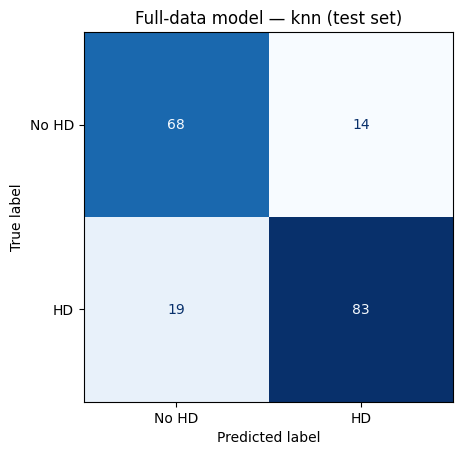

,approach,test_f1,test_acc,test_auc,n_test
0,per-subgroup (pooled champions),0.844,0.832,NaN,184
1,full-data (Age + Sex as features),0.834,0.821,0.88,184


In [109]:
# Champion = best CV F1 among all candidates (5 base models + voting + stacking); test once.
full_champion = max(full_candidate_f1, key=full_candidate_f1.get)
full_pipe = make_full_candidate(full_champion).fit(Xf_tr, yf_tr)
yf_pred = full_pipe.predict(Xf_te)

print(f"Full-data champion: {full_champion} "
      f"(CV F1={full_candidate_f1[full_champion]:.3f})\n")
print(classification_report(yf_te, yf_pred, target_names=["No HD", "HD"]))

ConfusionMatrixDisplay(
    confusion_matrix(yf_te, yf_pred), display_labels=["No HD", "HD"]
).plot(colorbar=False, cmap="Blues")
plt.title(f"Full-data model — {full_champion} (test set)")
plt.show()

# Head-to-head on the SAME 184 held-out test rows: full-data model vs per-subgroup pooled champions.
comparison = [{
    "approach": "full-data (Age + Sex as features)",
    "test_f1": round(f1_score(yf_te, yf_pred), 3),
    "test_acc": round(accuracy_score(yf_te, yf_pred), 3),
    "test_auc": round(roc_auc_score(yf_te, positive_scores(full_pipe, Xf_te)), 3),
    "n_test": len(yf_te),
}]
if "all_pred" in globals():   # requires the per-subgroup confusion-matrix cell to have run
    comparison.insert(0, {
        "approach": "per-subgroup (pooled champions)",
        "test_f1": round(f1_score(all_true, all_pred), 3),
        "test_acc": round(accuracy_score(all_true, all_pred), 3),
        "test_auc": np.nan,   # pooled labels only; no shared probability scale across subgroups
        "n_test": len(all_true),
    })
pd.DataFrame(comparison)

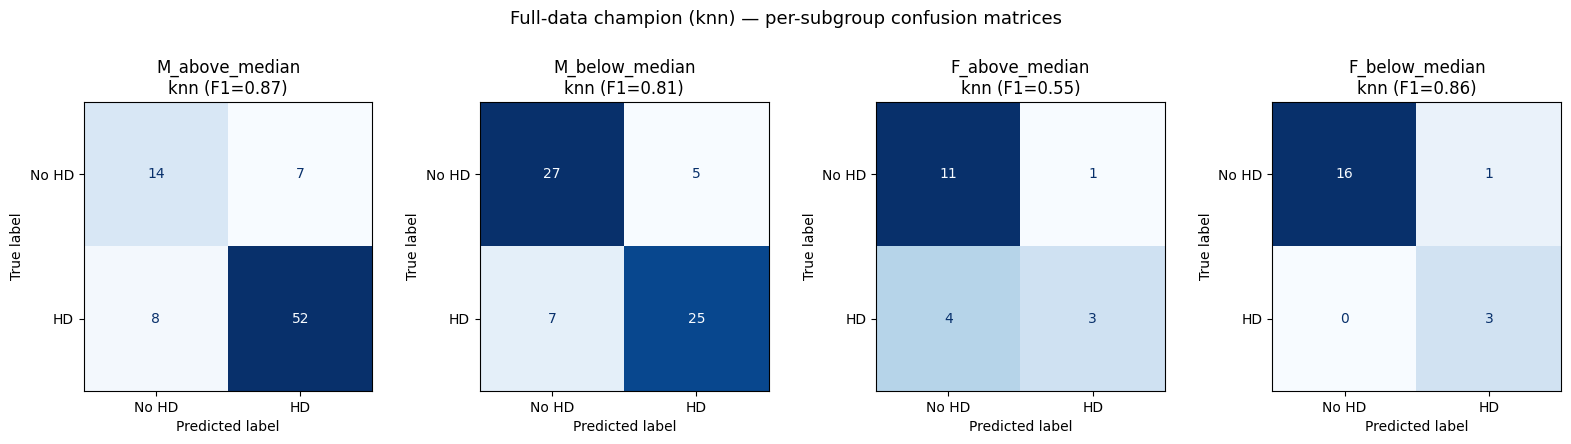

In [113]:
# Full-data champion scored on each subgroup's exact test rows.
labels = ["No HD", "HD"]
fd_true, fd_pred = [], []
fig, axes = plt.subplots(1, len(splits), figsize=(4 * len(splits), 4))
for ax, g in zip(axes, splits):
    idx = splits[g][1].index
    y_true = splits[g][3]
    y_pred = full_pipe.predict(heart_df.loc[idx, full_features])
    fd_true.extend(y_true)
    fd_pred.extend(y_pred)
    ConfusionMatrixDisplay(
        confusion_matrix(y_true, y_pred), display_labels=labels
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{g}\n{full_champion} (F1={f1_score(y_true, y_pred):.2f})")
fig.suptitle(f"Full-data champion ({full_champion}) — per-subgroup confusion matrices",
             y=1.05, fontsize=13)
plt.tight_layout()
plt.show()


## Per-Subgroup Comparison (same split, same test rows)

Both approaches use the one shared 80/20 split, they can be compared **per subgroup on identical test rows**. 

In [115]:
# The Full-Data Benchmark already trained full_pipe on the shared train pool (= union of the
# subgroup train splits), so we reuse it directly — same split, same model. Its predictions on
# each subgroup's test rows carry no leakage (those rows are held out of the shared train pool).
full_cmp = full_pipe

per_group_cmp = []
for c in champions:                     # per-subgroup champions from the confusion-matrix cell
    test_idx = splits[c["group"]][1].index
    y_true = c["y_true"]
    full_pred = full_cmp.predict(heart_df.loc[test_idx, full_features])
    per_group_cmp.append({
        "group": c["group"],
        "n_test": len(test_idx),
        "subgroup_model": c["champion"],
        "subgroup_f1": round(f1_score(y_true, c["y_pred"]), 3),
        "subgroup_acc": round(accuracy_score(y_true, c["y_pred"]), 3),
        "fulldata_f1": round(f1_score(y_true, full_pred), 3),
        "fulldata_acc": round(accuracy_score(y_true, full_pred), 3),
    })

# Pooled row over the identical test set (both methods on the same 184 rows).
pooled_true = np.concatenate([c["y_true"] for c in champions])
pooled_sub = np.concatenate([c["y_pred"] for c in champions])
pooled_full = np.concatenate(
    [full_cmp.predict(heart_df.loc[splits[c["group"]][1].index, full_features]) for c in champions])
per_group_cmp.append({
    "group": "ALL (pooled)",
    "n_test": len(pooled_true),
    "subgroup_model": "per-group champions",
    "subgroup_f1": round(f1_score(pooled_true, pooled_sub), 3),
    "subgroup_acc": round(accuracy_score(pooled_true, pooled_sub), 3),
    "fulldata_f1": round(f1_score(pooled_true, pooled_full), 3),
    "fulldata_acc": round(accuracy_score(pooled_true, pooled_full), 3),
})

subgroup_vs_fulldata = pd.DataFrame(per_group_cmp)
subgroup_vs_fulldata

,group,n_test,subgroup_model,subgroup_f1,subgroup_acc,fulldata_f1,fulldata_acc
0,M_above_median,81,knn,0.883,0.827,0.874,0.815
1,M_below_median,64,random_forest,0.806,0.812,0.806,0.812
2,F_above_median,19,random_forest,0.545,0.737,0.545,0.737
3,F_below_median,20,voting,1.000,1.000,0.857,0.950
4,ALL (pooled),184,per-group champions,0.844,0.832,0.834,0.821


## Conclusion


The best models reach roughly **0.83–0.84 test F1, ~0.82 accuracy, and ~0.88 ROC-AUC** on the held-out set.

### Subgrouping vs. a single full-data model
Splitting by Sex/Age and training four specialised models gave **no real advantage** over one model trained on all the data with Age and Sex as ordinary features:

| approach | test F1 | test acc | test AUC |
|---|---|---|---|
| per-subgroup  | 0.844 | 0.832 | — |
| full-data  | 0.834 | 0.821 | 0.88 |

### On model choice and ensembles
- For the sub-group version ensembles add value as for below median female voting is used. Though the difference is small compared to other models.
- All models cluster tightly (0.87–0.89 CV F1 on the full data), so **algorithm choice is not the bottleneck** — the data and features set the ceiling. The full-data champion was simply KNN.
- **Voting and stacking did not beat the best single model** (KNN 0.892 vs voting 0.883, stacking 0.886).

### Caveats
- The female subgroups (~19–20 test rows) are too small for trustworthy per-group numbers — this fragmentation of the already-scarce female-positive cases is the concrete cost of subgrouping.
- `Cholesterol` and `RestingBP` were excluded.

- Scores come from a single train/test split. Different train/test splits can be tried.

- Consistent with the EDA, `ST_Slope`, `ChestPainType`, and `ExerciseAngina` are the strongest drivers of the predictions.

### Final Note

I still do believe that splitting the dataset into sub-groups based on age and sex is valuable, even though the results does not support this. The main problem is the size of the dataset, with a large enough dataset I believe this claim can be supported.